## Experimento 04: Generalización Inter-Sujeto Plug-and-Play (Leave-One-Subject-Out CV)

**Proyecto:** MyoTensor — Clasificación Mioeléctrica Embebida en ESP32-S3  
**Fase 2:** Generalización Poblacional e Inter-Sujeto (Evaluación Dual FDS y ED)  
**Estado:** Activo / Por Ejecutar  
**Pipeline de Preprocesamiento Estandarizado:** Ventana $W = 250\text{ ms}$, Stride $S = 50\text{ ms}$, Steady-State (recorte simétrico de 500 ms onset / 500 ms offset) y normalización por %MVC (`valid_flag == 1`).

---

### 1. Introducción y Fundamento Metodológico

En aplicaciones protésicas y de rehabilitación motora reales, un paciente nuevo se coloca la prótesis sin haber pasado por una sesión previa de recolección y entrenamiento exhaustivo de modelos. Este escenario de transferencia en frío (*Zero-Shot User Transfer*) o funcionamiento **Plug-and-Play** constituye el desafío más exigente en interfaces mioeléctricas, debido a la notable **variabilidad anatómica y fisiológica entre personas**:
- Diferencias en espesor de tejido adiposo subcutáneo y masa muscular.
- Variaciones sutiles en la posición angular y longitudinal de los electrodos respecto a los puntos motores.
- Discrepancias en impedancia de contacto piel-electrodo y velocidad de conducción de los potenciales de acción de unidad motora (MUAPs).

### 2. Objetivos del Experimento 04
1. **Evaluar la Robustez Inter-Sujeto:** Medir la exactitud y estabilidad del sistema ante sujetos completamente no vistos utilizando **Validación Cruzada Dejando un Sujeto Fuera (*Leave-One-Subject-Out Cross-Validation, LOSO-CV*)** sobre los 10 participantes ($N = 10$, de `S01` a `S10`).
2. **Evaluación Dual FDS vs ED:** Contrastar si el canal flexor (**FDS**) o el canal extensor (**ED**) presenta menor degradación frente a la variabilidad poblacional.
3. **Comparar Machine Learning vs Deep Learning:** Determinar si los rasgos manuales fijos (RF, SVM) o las representaciones espaciotemporales aprendidas directamente de la señal cruda (CNN-LSTM, CNN-TCN) son más invariantes entre diferentes individuos.
4. **Cuantificar la Brecha de Generalización (*Generalization Gap*):**
   $$\Delta_{\text{LOSO}} = \text{F1}_{\text{Pooled (Exp 03)}} - \text{F1}_{\text{LOSO (Exp 04)}}$$
5. **Persistencia de Modelos Pre-entrenados para la Fase 2C:** Guardar los modelos entrenados en cada fold para alimentar directamente el **Experimento 05 (Fine-Tuning / Calibración Rápida de 3 a 5 s)**.

---

### 3. Esquema de Validación Cruzada (10 Folds por Músculo)

Para cada músculo $\in \{\text{FDS}, \text{ED}\}$ y para cada iteración de sujeto $k \in \{1, \dots, 10\}$:
- **Held-Out Test Set:** 100% de las ventanas del sujeto $S_k$ (sujeto no visto).
- **Training Set:** La totalidad de datos de los 9 sujetos restantes ($N - 1 = 9$).
- **Aislamiento Estricto:** El escalador de características `StandardScaler` se ajusta (*fit*) exclusivamente con los 9 sujetos de entrenamiento y se aplica (*transform*) al sujeto de prueba.
- **Total de Evaluaciones:** $2 \text{ músculos} \times 10 \text{ folds} \times 4 \text{ modelos} = 80 \text{ entrenamientos independientes}$.

---

In [1]:
import os
import sys
import time
import json
import joblib
from pathlib import Path

# 1. Configuración de Variables de Entorno y GPU
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# 2. Resolución dinámica del directorio raíz 'intelligence'
curr = Path.cwd().resolve()
intelligence_dir = None
while curr != curr.parent:
    if (curr / "intelligence" / "src").is_dir():
        intelligence_dir = curr / "intelligence"
        break
    elif (curr / "src").is_dir() and curr.name == "intelligence":
        intelligence_dir = curr
        break
    curr = curr.parent

if intelligence_dir is None:
    raise RuntimeError("No se pudo localizar el directorio raíz 'intelligence'")

if str(intelligence_dir) not in sys.path:
    sys.path.insert(0, str(intelligence_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

# Detección y activación de GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"🚀 GPU detectada y activada: {gpus[0].name}")
    except RuntimeError as e:
        print(f"⚠️ Aviso GPU: {e}")
else:
    print("ℹ️ Ejecutando en CPU.")

# 3. Importación de módulos de MyoTensor
from src import config, dataset, features
from src.models import rf, svm, cnn_lstm, cnn_tcn

# 4. Configuración gráfica para publicación científica
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.titlesize'] = 14

print(f"✅ Módulos importados exitosamente desde: {intelligence_dir}")
print(f"   Configuración: Ventana W={config.WINDOW_SIZE} ms, Stride S={config.STRIDE} ms, Steady-State=True, MVC=True.")

I0000 00:00:1789944345.869293   48932 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


ℹ️ Ejecutando en CPU.
✅ Módulos importados exitosamente desde: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence
   Configuración: Ventana W=250 ms, Stride S=50 ms, Steady-State=True, MVC=True.


I0000 00:00:1789944346.712004   48932 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
E0000 00:00:1789944346.826547   48932 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_UNKNOWN: unknown error


In [2]:
MUSCLES = ["FDS", "ED"]
ALL_SUBJECTS = [f"S{i:02d}" for i in range(1, 11)]
GESTURES = config.GESTURES

def preload_subjects_data(muscles=MUSCLES, subjects=ALL_SUBJECTS):
    """
    Pre-carga y pre-extrae en memoria los datos de todos los sujetos para FDS y ED.
    Garantiza que cada sujeto use su respectivo umbral de ruido calibrado para ZC y SSC.
    """
    cache = {}
    print(f"\n{'='*80}")
    print(f" PRE-CARGANDO Y EXTRAYENDO CARACTERÍSTICAS DE LOS {len(subjects)} SUJETOS")
    print(f"{'='*80}")
    
    for muscle in muscles:
        cache[muscle] = {}
        t0 = time.time()
        for s in subjects:
            X_tr, y_tr, X_te, y_te = dataset.load_and_segment_dataset(
                subject=s,
                muscle=muscle,
                window_size=config.WINDOW_SIZE,
                overlap=config.STRIDE,
                apply_mvc=True,
                steady_state_only=True
            )
            # Unir todo el registro validado del sujeto
            X_s = np.concatenate([X_tr, X_te], axis=0)
            y_s = np.concatenate([y_tr, y_te], axis=0)
            
            # Extracción de características temporales con umbral de ruido calibrado individual
            feat_s = features.extract_features(X_s, subject=s, muscle=muscle)
            
            cache[muscle][s] = {
                "X_raw": X_s,
                "y": y_s,
                "X_feat": feat_s
            }
        dt = time.time() - t0
        total_w = sum(len(cache[muscle][s]["y"]) for s in subjects)
        print(f"  [+] {muscle}: {len(subjects)} sujetos cargados ({total_w:,} ventanas totales) en {dt:.2f}s")
        
    return cache

def run_loso_cross_validation(data_cache, muscles=MUSCLES, subjects=ALL_SUBJECTS, save_models=True):
    """
    Ejecuta el protocolo completo de Leave-One-Subject-Out Cross-Validation (LOSO-CV).
    Evalúa los 4 modelos (RF, SVM, CNN-LSTM, CNN-TCN) en 10 folds para FDS y ED.
    Opcionalmente exporta los modelos entrenados a disco para el Experimento 05 (Fine-Tuning).
    """
    models_dir = intelligence_dir / "src" / "experimentos" / "logs" / "models_loso"
    if save_models:
        os.makedirs(models_dir, exist_ok=True)
        
    fold_records = []
    confusion_matrices_dict = {}
    
    total_runs = len(muscles) * len(subjects) * 4
    run_counter = 0
    t_global = time.time()
    
    print(f"\n{'='*85}")
    print(f" INICIANDO EXPERIMENTO 04 — LEAVE-ONE-SUBJECT-OUT CROSS-VALIDATION (LOSO-CV)")
    print(f" Total de evaluaciones: {total_runs} ({len(muscles)} músculos × {len(subjects)} folds × 4 modelos)")
    print(f"{'='*85}\n")
    
    for muscle in muscles:
        confusion_matrices_dict[muscle] = {s: {} for s in subjects}
        print(f"\n{'#'*80}")
        print(f" >>> EVALUANDO MÚSCULO: {muscle} <<<")
        print(f"{'#'*80}")
        
        # Obtener hiperparámetros óptimos de config.py
        rf_params = config.get_model_hyperparams("RF", muscle=muscle)
        svm_params = config.get_model_hyperparams("SVM", muscle=muscle)
        lstm_params = config.get_model_hyperparams("CNN-LSTM", muscle=muscle)
        tcn_params = config.get_model_hyperparams("CNN-TCN", muscle=muscle)
        
        for fold_idx, test_subj in enumerate(subjects):
            train_subjs = [s for s in subjects if s != test_subj]
            t_fold_start = time.time()
            
            print(f"\n--------------------------------------------------------------------------------")
            print(f" [{muscle}] Fold {fold_idx+1}/{len(subjects)} — Test Subject: {test_subj} | Train: {len(train_subjs)} sujetos")
            print(f"--------------------------------------------------------------------------------")
            
            # 1. Ensamblar conjuntos de entrenamiento y prueba
            X_train_raw = np.concatenate([data_cache[muscle][s]["X_raw"] for s in train_subjs], axis=0)
            y_train     = np.concatenate([data_cache[muscle][s]["y"] for s in train_subjs], axis=0)
            X_test_raw  = data_cache[muscle][test_subj]["X_raw"]
            y_test      = data_cache[muscle][test_subj]["y"]
            
            X_train_feat = np.concatenate([data_cache[muscle][s]["X_feat"] for s in train_subjs], axis=0)
            X_test_feat  = data_cache[muscle][test_subj]["X_feat"]
            
            # Escalador ajustado ESTRICTAMENTE sobre los 9 sujetos de entrenamiento
            scaler = StandardScaler()
            X_train_feat_sc = scaler.fit_transform(X_train_feat)
            X_test_feat_sc  = scaler.transform(X_test_feat)
            
            # -------------------------------------------------------------
            # A. Random Forest
            # -------------------------------------------------------------
            run_counter += 1
            t0 = time.time()
            model_rf = rf.train(X_train_feat, y_train, muscle=muscle)
            t_rf = time.time() - t0
            res_rf = rf.evaluate(model_rf, X_test_feat, y_test)
            confusion_matrices_dict[muscle][test_subj]["RF"] = res_rf["confusion_matrix"]
            confusion_matrices_dict[muscle][test_subj]["Random Forest"] = res_rf["confusion_matrix"]
            
            if save_models:
                joblib.dump(model_rf, models_dir / f"loso_{muscle}_RF_{test_subj}.joblib")
                
            fold_records.append({
                "Muscle": muscle,
                "Fold": fold_idx + 1,
                "Test_Subject": test_subj,
                "Model": "Random Forest",
                "Test_Accuracy": res_rf["accuracy"],
                "Test_F1_Macro": res_rf["f1_macro"],
                "Test_Precision_Macro": res_rf["precision_macro"],
                "Test_Recall_Macro": res_rf["recall_macro"],
                "F1_Reposo": res_rf["f1_per_class"][0],
                "F1_Palma": res_rf["f1_per_class"][1],
                "F1_Puño": res_rf["f1_per_class"][2],
                "F1_Paz": res_rf["f1_per_class"][3],
                "Train_Time_s": t_rf
            })
            print(f"  [1/4] RF       -> F1-Macro: {res_rf['f1_macro']*100:.2f}% | Acc: {res_rf['accuracy']*100:.2f}% ({t_rf:.2f}s)")
            
            # -------------------------------------------------------------
            # B. Support Vector Machine (SVM)
            # -------------------------------------------------------------
            run_counter += 1
            t0 = time.time()
            model_svm = svm.train(X_train_feat_sc, y_train, muscle=muscle)
            t_svm = time.time() - t0
            res_svm = svm.evaluate(model_svm, X_test_feat_sc, y_test)
            confusion_matrices_dict[muscle][test_subj]["SVM"] = res_svm["confusion_matrix"]
            
            if save_models:
                joblib.dump(model_svm, models_dir / f"loso_{muscle}_SVM_{test_subj}.joblib")
                
            fold_records.append({
                "Muscle": muscle,
                "Fold": fold_idx + 1,
                "Test_Subject": test_subj,
                "Model": "SVM",
                "Test_Accuracy": res_svm["accuracy"],
                "Test_F1_Macro": res_svm["f1_macro"],
                "Test_Precision_Macro": res_svm["precision_macro"],
                "Test_Recall_Macro": res_svm["recall_macro"],
                "F1_Reposo": res_svm["f1_per_class"][0],
                "F1_Palma": res_svm["f1_per_class"][1],
                "F1_Puño": res_svm["f1_per_class"][2],
                "F1_Paz": res_svm["f1_per_class"][3],
                "Train_Time_s": t_svm
            })
            print(f"  [2/4] SVM      -> F1-Macro: {res_svm['f1_macro']*100:.2f}% | Acc: {res_svm['accuracy']*100:.2f}% ({t_svm:.2f}s)")
            
            # -------------------------------------------------------------
            # C. CNN-LSTM (DL Recurrente)
            # -------------------------------------------------------------
            run_counter += 1
            t0 = time.time()
            model_lstm = cnn_lstm.train(
                X_train_raw, y_train,
                muscle=muscle,
                epochs=25,
                batch_size=128,
                verbose=0
            )
            t_lstm = time.time() - t0
            res_lstm = cnn_lstm.evaluate(model_lstm, X_test_raw, y_test)
            confusion_matrices_dict[muscle][test_subj]["CNN-LSTM"] = res_lstm["confusion_matrix"]
            
            if save_models:
                model_lstm.save(models_dir / f"loso_{muscle}_CNN-LSTM_{test_subj}.keras")
                
            fold_records.append({
                "Muscle": muscle,
                "Fold": fold_idx + 1,
                "Test_Subject": test_subj,
                "Model": "CNN-LSTM",
                "Test_Accuracy": res_lstm["accuracy"],
                "Test_F1_Macro": res_lstm["f1_macro"],
                "Test_Precision_Macro": res_lstm["precision_macro"],
                "Test_Recall_Macro": res_lstm["recall_macro"],
                "F1_Reposo": res_lstm["f1_per_class"][0],
                "F1_Palma": res_lstm["f1_per_class"][1],
                "F1_Puño": res_lstm["f1_per_class"][2],
                "F1_Paz": res_lstm["f1_per_class"][3],
                "Train_Time_s": t_lstm
            })
            print(f"  [3/4] CNN-LSTM -> F1-Macro: {res_lstm['f1_macro']*100:.2f}% | Acc: {res_lstm['accuracy']*100:.2f}% ({t_lstm:.2f}s)")
            
            # -------------------------------------------------------------
            # D. CNN-TCN (DL Convolucional Dilatado)
            # -------------------------------------------------------------
            run_counter += 1
            t0 = time.time()
            model_tcn = cnn_tcn.train(
                X_train_raw, y_train,
                muscle=muscle,
                epochs=25,
                batch_size=128,
                verbose=0
            )
            t_tcn = time.time() - t0
            res_tcn = cnn_tcn.evaluate(model_tcn, X_test_raw, y_test)
            confusion_matrices_dict[muscle][test_subj]["CNN-TCN"] = res_tcn["confusion_matrix"]
            
            if save_models:
                model_tcn.save(models_dir / f"loso_{muscle}_CNN-TCN_{test_subj}.keras")
                
            fold_records.append({
                "Muscle": muscle,
                "Fold": fold_idx + 1,
                "Test_Subject": test_subj,
                "Model": "CNN-TCN",
                "Test_Accuracy": res_tcn["accuracy"],
                "Test_F1_Macro": res_tcn["f1_macro"],
                "Test_Precision_Macro": res_tcn["precision_macro"],
                "Test_Recall_Macro": res_tcn["recall_macro"],
                "F1_Reposo": res_tcn["f1_per_class"][0],
                "F1_Palma": res_tcn["f1_per_class"][1],
                "F1_Puño": res_tcn["f1_per_class"][2],
                "F1_Paz": res_tcn["f1_per_class"][3],
                "Train_Time_s": t_tcn
            })
            print(f"  [4/4] CNN-TCN  -> F1-Macro: {res_tcn['f1_macro']*100:.2f}% | Acc: {res_tcn['accuracy']*100:.2f}% ({t_tcn:.2f}s)")
            print(f"  >> Fold {fold_idx+1} completado en {time.time()-t_fold_start:.1f}s (Progreso global: {run_counter}/{total_runs})")
            
    df_loso = pd.DataFrame(fold_records)
    total_min = (time.time() - t_global) / 60
    print(f"\n{'='*85}")
    print(f" ✅ EXPERIMENTO 04 (LOSO-CV) COMPLETADO EN {total_min:.2f} MINUTOS")
    if save_models:
        print(f" 💾 Modelos pre-entrenados guardados en: {models_dir}")
    print(f"{'='*85}\n")
    return df_loso, confusion_matrices_dict

In [3]:
# 1. Pre-cargar datos de los 10 sujetos
data_cache = preload_subjects_data(muscles=MUSCLES, subjects=ALL_SUBJECTS)

# 2. Ejecutar Leave-One-Subject-Out Cross-Validation
df_loso_results, cm_loso = run_loso_cross_validation(
    data_cache=data_cache,
    muscles=MUSCLES,
    subjects=ALL_SUBJECTS,
    save_models=True
)

# 3. Exportar resultados brutos por fold a CSV
logs_dir = intelligence_dir / "src" / "experimentos" / "logs"
os.makedirs(logs_dir, exist_ok=True)
csv_output = logs_dir / "exp04_generalizacion_loso_resultados.csv"
df_loso_results.to_csv(csv_output, index=False)
print(f"📁 Resultados brutos de LOSO-CV exportados a: {csv_output}")


 PRE-CARGANDO Y EXTRAYENDO CARACTERÍSTICAS DE LOS 10 SUJETOS
  [+] FDS: 10 sujetos cargados (39,519 ventanas totales) en 2.74s
  [+] ED: 10 sujetos cargados (39,652 ventanas totales) en 2.79s

 INICIANDO EXPERIMENTO 04 — LEAVE-ONE-SUBJECT-OUT CROSS-VALIDATION (LOSO-CV)
 Total de evaluaciones: 80 (2 músculos × 10 folds × 4 modelos)


################################################################################
 >>> EVALUANDO MÚSCULO: FDS <<<
################################################################################

--------------------------------------------------------------------------------
 [FDS] Fold 1/10 — Test Subject: S01 | Train: 9 sujetos
--------------------------------------------------------------------------------
  [1/4] RF       -> F1-Macro: 36.43% | Acc: 49.33% (0.91s)
  [2/4] SVM      -> F1-Macro: 38.34% | Acc: 48.65% (9.16s)
  [3/4] CNN-LSTM -> F1-Macro: 53.09% | Acc: 62.41% (174.60s)
  [4/4] CNN-TCN  -> F1-Macro: 47.62% | Acc: 54.93% (256.95s)
  >> Fold 1

### 3. Resultados y Métricas Estadísticas de Generalización Inter-Sujeto

A continuación se presentan las estadísticas inter-sujeto (promedio $\mu$ y desviación estándar $\sigma$) para los 10 sujetos no vistos, así como el desglose por cada participante y la brecha respecto al escenario ideal poblacional (**Experimento 03**).

In [4]:
# -------------------------------------------------------------
# 1. Tabla de Estadísticas Inter-Sujeto (Media ± Desviación Estándar)
# -------------------------------------------------------------
summary_records = []

for (muscle, model), group in df_loso_results.groupby(["Muscle", "Model"]):
    mean_f1 = group["Test_F1_Macro"].mean()
    std_f1  = group["Test_F1_Macro"].std()
    mean_acc = group["Test_Accuracy"].mean()
    std_acc  = group["Test_Accuracy"].std()
    mean_prec = group["Test_Precision_Macro"].mean()
    std_prec  = group["Test_Precision_Macro"].std()
    mean_rec = group["Test_Recall_Macro"].mean()
    std_rec  = group["Test_Recall_Macro"].std()
    
    mean_rep = group["F1_Reposo"].mean()
    mean_pal = group["F1_Palma"].mean()
    mean_pun = group["F1_Puño"].mean()
    mean_paz = group["F1_Paz"].mean()
    
    cv_stability = (std_f1 / mean_f1) * 100 if mean_f1 > 0 else 0
    mean_time = group["Train_Time_s"].mean()
    
    summary_records.append({
        "Muscle": muscle,
        "Model": model,
        "F1_Macro_Mean": mean_f1,
        "F1_Macro_Std": std_f1,
        "Accuracy_Mean": mean_acc,
        "Accuracy_Std": std_acc,
        "F1_Macro_Summary": f"{mean_f1*100:.2f}% ± {std_f1*100:.2f}%",
        "Accuracy_Summary": f"{mean_acc*100:.2f}% ± {std_acc*100:.2f}%",
        "Precision_Summary": f"{mean_prec*100:.2f}% ± {std_prec*100:.2f}%",
        "Recall_Summary": f"{mean_rec*100:.2f}% ± {std_rec*100:.2f}%",
        "F1_Reposo": f"{mean_rep*100:.1f}%",
        "F1_Palma": f"{mean_pal*100:.1f}%",
        "F1_Puño": f"{mean_pun*100:.1f}%",
        "F1_Paz": f"{mean_paz*100:.1f}%",
        "CV_Variability": f"{cv_stability:.1f}%",
        "Avg_Train_Time_s": f"{mean_time:.1f} s"
    })

df_summary = pd.DataFrame(summary_records)

for muscle in MUSCLES:
    print(f"\n{'='*90}")
    print(f" TABLA ESTADÍSTICA INTER-SUJETO (LOSO-CV, N=10) — MÚSCULO: {muscle}")
    print(f"{'='*90}")
    df_m = df_summary[df_summary["Muscle"] == muscle][[
        "Model", "F1_Macro_Summary", "Accuracy_Summary", "Precision_Summary", "Recall_Summary",
        "F1_Reposo", "F1_Palma", "F1_Puño", "F1_Paz", "CV_Variability", "Avg_Train_Time_s"
    ]].copy()
    display(df_m)

# -------------------------------------------------------------
# 2. Análisis de Brecha de Generalización (Generalization Gap vs Exp 03)
# -------------------------------------------------------------
csv_exp03 = logs_dir / "exp03_evaluacion_poblacional_resultados.csv"
if csv_exp03.exists():
    df_exp03 = pd.read_csv(csv_exp03)
    gap_records = []
    for _, row in df_summary.iterrows():
        m = row["Muscle"]
        mod = row["Model"]
        row_03 = df_exp03[(df_exp03["Muscle"] == m) & (df_exp03["Model"] == mod)]
        if not row_03.empty:
            f1_pooled = row_03["Test_F1_Macro"].values[0]
            f1_loso = row["F1_Macro_Mean"]
            gap = (f1_pooled - f1_loso) * 100
            gap_records.append({
                "Muscle": m,
                "Model": mod,
                "F1_Pooled_Exp03": f"{f1_pooled*100:.2f}%",
                "F1_LOSO_Mean": f"{f1_loso*100:.2f}%",
                "Generalization_Gap": f"-{gap:.2f} pp" if gap >= 0 else f"+{-gap:.2f} pp",
                "Retention_Rate": f"{(f1_loso / f1_pooled)*100:.1f}%"
            })
    print(f"\n{'='*90}")
    print(" ANÁLISIS DE LA BRECHA DE GENERALIZACIÓN (POOLED EXP 03 vs LOSO-CV EXP 04)")
    print(f"{'='*90}")
    df_gap = pd.DataFrame(gap_records)
    display(df_gap)

# -------------------------------------------------------------
# 3. Desglose de F1-Macro por Sujeto y Modelo (Matriz de Sujetos)
# -------------------------------------------------------------
print(f"\n{'='*90}")
print(" DESGLOSE DE F1-MACRO POR SUJETO (TEST SUJETO EXCLUIDO)")
print(f"{'='*90}")
pivot_loso = df_loso_results.pivot_table(
    index=["Muscle", "Test_Subject"],
    columns="Model",
    values="Test_F1_Macro"
)
display((pivot_loso * 100).round(2).astype(str) + "%")


 TABLA ESTADÍSTICA INTER-SUJETO (LOSO-CV, N=10) — MÚSCULO: FDS


,Model,F1_Macro_Summary,Accuracy_Summary,Precision_Summary,Recall_Summary,F1_Reposo,F1_Palma,F1_Puño,F1_Paz,CV_Variability,Avg_Train_Time_s
4,CNN-LSTM,54.75% ± 12.62%,62.02% ± 13.44%,58.36% ± 15.97%,57.37% ± 10.99%,84.3%,40.7%,66.0%,28.0%,23.0%,181.9 s
5,CNN-TCN,51.48% ± 13.49%,59.01% ± 16.02%,54.74% ± 16.84%,54.69% ± 12.24%,77.8%,42.2%,63.3%,22.6%,26.2%,259.8 s
6,Random Forest,50.83% ± 9.14%,60.58% ± 8.64%,53.29% ± 8.80%,53.36% ± 8.66%,92.3%,35.7%,56.1%,19.3%,18.0%,0.9 s
7,SVM,51.96% ± 10.41%,61.72% ± 10.53%,55.59% ± 9.68%,55.09% ± 11.22%,91.4%,36.7%,61.0%,18.7%,20.0%,10.3 s



 TABLA ESTADÍSTICA INTER-SUJETO (LOSO-CV, N=10) — MÚSCULO: ED


,Model,F1_Macro_Summary,Accuracy_Summary,Precision_Summary,Recall_Summary,F1_Reposo,F1_Palma,F1_Puño,F1_Paz,CV_Variability,Avg_Train_Time_s
0,CNN-LSTM,51.13% ± 21.17%,55.93% ± 20.68%,57.53% ± 15.39%,53.55% ± 17.91%,72.6%,42.0%,41.1%,48.9%,41.4%,188.8 s
1,CNN-TCN,51.07% ± 20.82%,55.96% ± 21.60%,55.04% ± 19.32%,53.24% ± 18.97%,72.7%,44.6%,33.5%,53.5%,40.8%,266.7 s
2,Random Forest,49.23% ± 11.50%,56.32% ± 11.68%,53.11% ± 9.60%,50.75% ± 10.25%,82.8%,39.7%,38.8%,35.7%,23.4%,0.4 s
3,SVM,51.35% ± 13.46%,58.95% ± 11.24%,54.48% ± 12.33%,52.99% ± 12.12%,88.4%,38.4%,34.3%,44.3%,26.2%,10.2 s



 ANÁLISIS DE LA BRECHA DE GENERALIZACIÓN (POOLED EXP 03 vs LOSO-CV EXP 04)


,Muscle,Model,F1_Pooled_Exp03,F1_LOSO_Mean,Generalization_Gap,Retention_Rate
0,ED,CNN-LSTM,79.96%,51.13%,-28.83 pp,63.9%
1,ED,CNN-TCN,80.19%,51.07%,-29.12 pp,63.7%
2,ED,Random Forest,71.14%,49.23%,-21.91 pp,69.2%
3,ED,SVM,72.99%,51.35%,-21.64 pp,70.4%
4,FDS,CNN-LSTM,79.78%,54.75%,-25.03 pp,68.6%
5,FDS,CNN-TCN,74.18%,51.48%,-22.70 pp,69.4%
6,FDS,Random Forest,70.49%,50.83%,-19.66 pp,72.1%
7,FDS,SVM,71.45%,51.96%,-19.48 pp,72.7%



 DESGLOSE DE F1-MACRO POR SUJETO (TEST SUJETO EXCLUIDO)


Model               CNN-LSTM CNN-TCN Random Forest     SVM
Muscle Test_Subject                                       
ED     S01            48.81%  50.75%        38.78%  41.42%
       S02            18.83%  20.49%        33.35%  33.23%
       S03            56.64%   62.2%        55.82%  61.82%
       S04            52.39%  52.89%        42.86%  48.46%
       S05            62.99%   54.1%        44.52%  49.14%
       S06            38.25%  39.89%        42.83%  36.34%
       S07            71.18%  81.16%         64.8%  70.51%
       S08            64.32%   55.4%        53.64%   54.6%
       S09            81.03%  76.46%        69.49%  72.43%
       S10            16.85%  17.36%        46.19%  45.53%
FDS    S01            53.09%  47.62%        36.43%  38.34%
       S02            66.88%  63.15%        59.72%  63.06%
       S03            66.55%  70.99%        61.92%  61.82%
       S04            60.38%  59.09%        56.22%  59.92%
       S05            23.22%  24.49%        40.88%  39.31%
       S06            57.98%  63.03%         60.5%  67.08%
       S07            48.37%  50.89%        47.42%  48.48%
       S08            52.06%  51.37%         40.6%  42.27%
       S09            56.78%  44.49%        51.84%  49.32%
       S10            62.19%  39.73%        52.75%  50.04%

/tmp/ipykernel_48932/271558703.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_48932/271558703.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


📊 Boxplots guardados en: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/exp04_loso_boxplots_f1.png


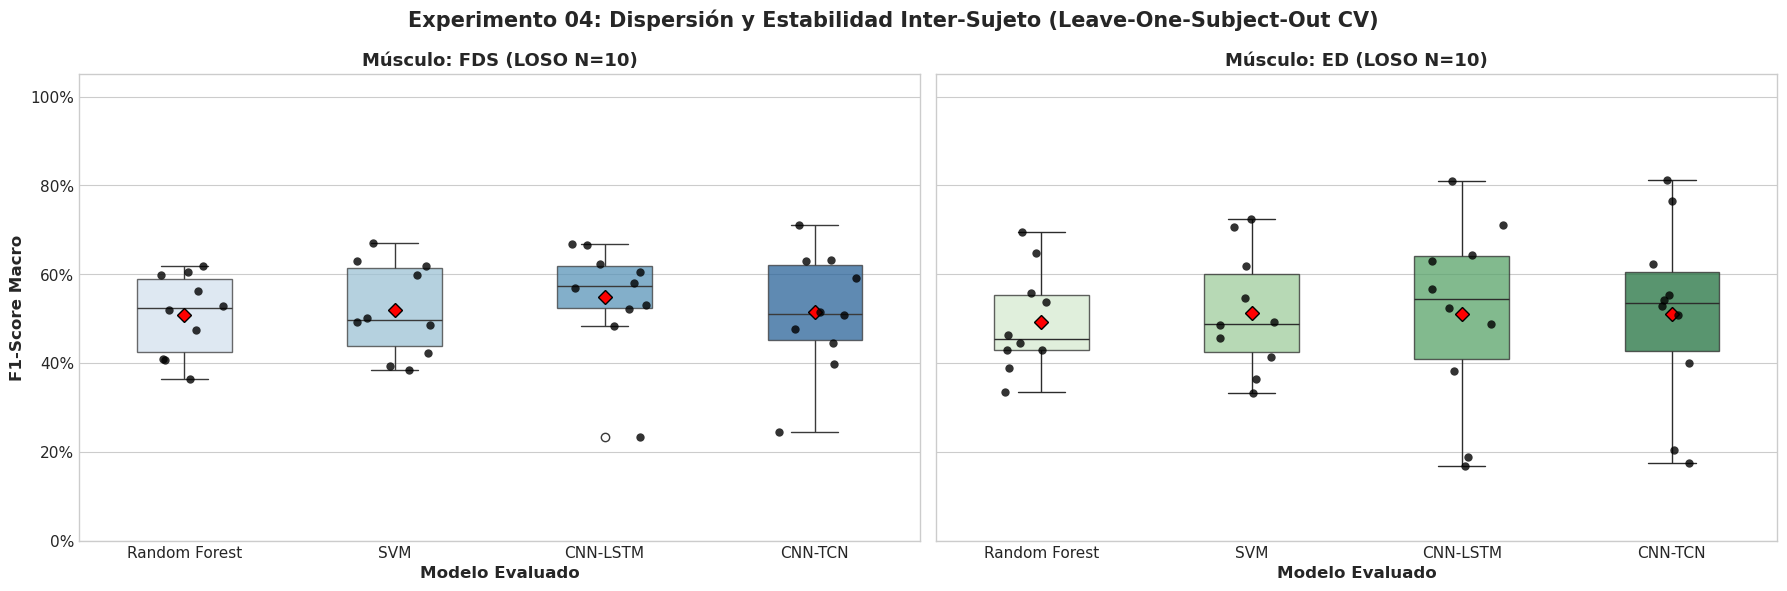

📊 Gráfico de barras guardado en: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/exp04_loso_comparativa_barras.png


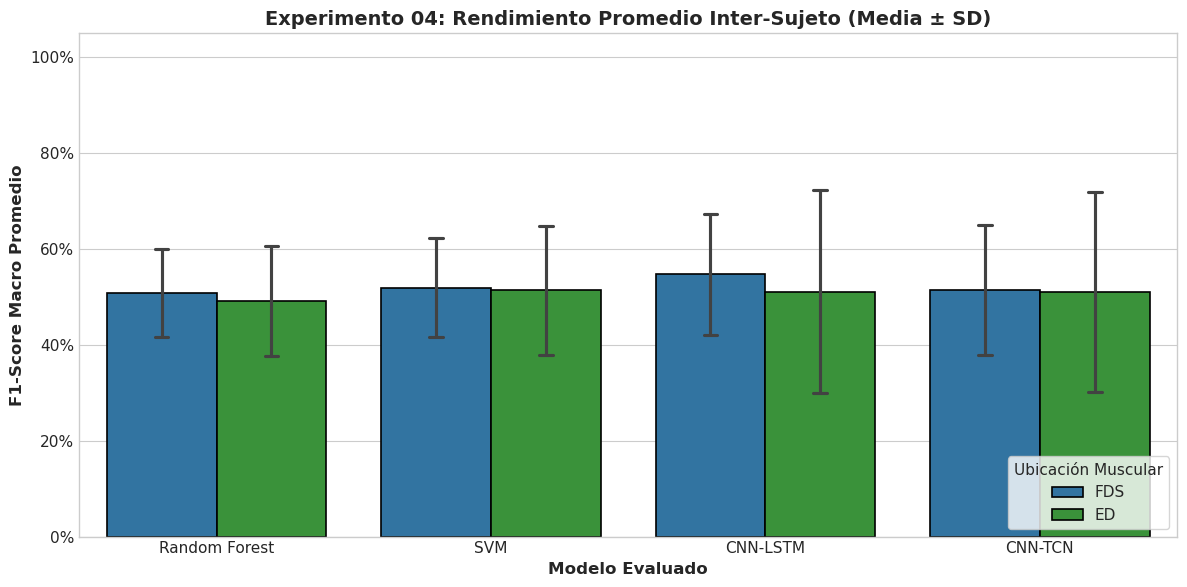

📊 Heatmap de sujetos guardado en: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/exp04_loso_heatmap_sujetos.png


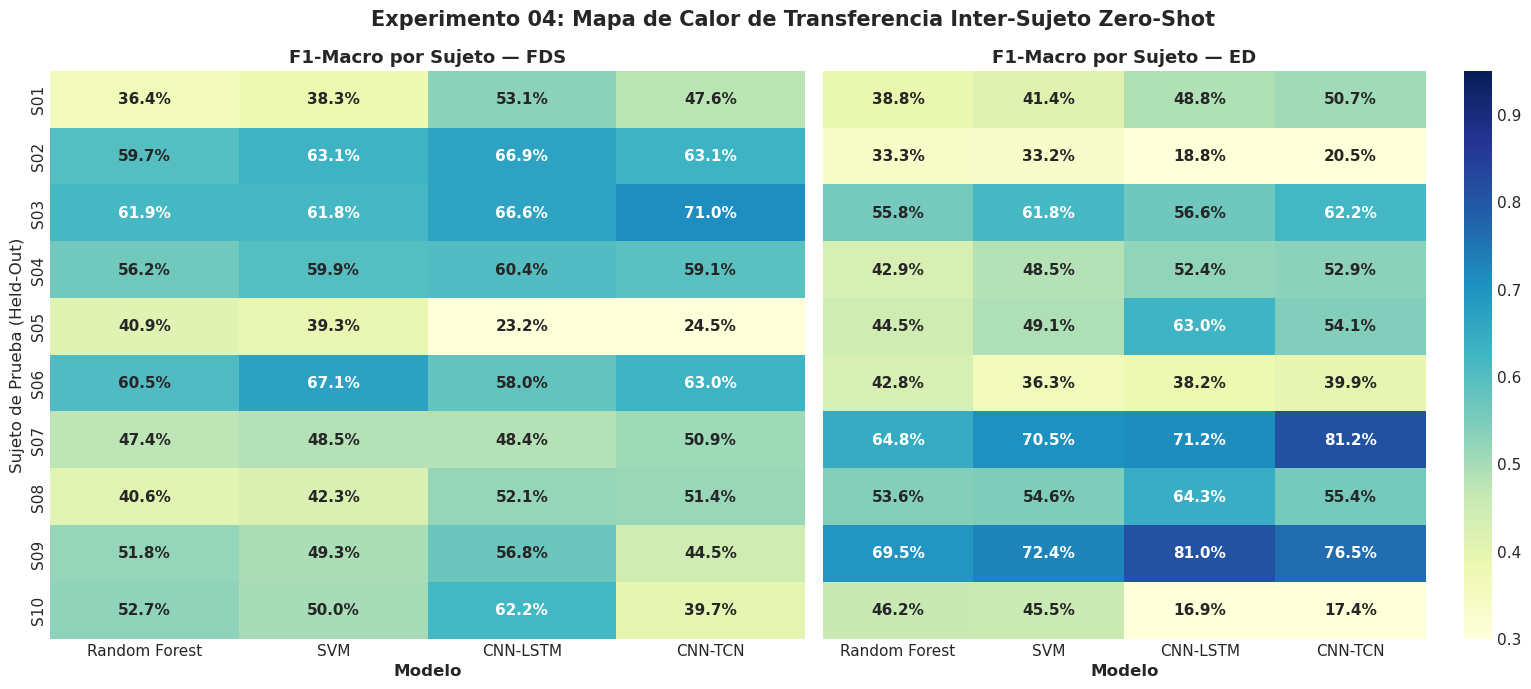

📊 Matrices de confusión acumuladas guardadas en: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/exp04_loso_matrices_confusion.png


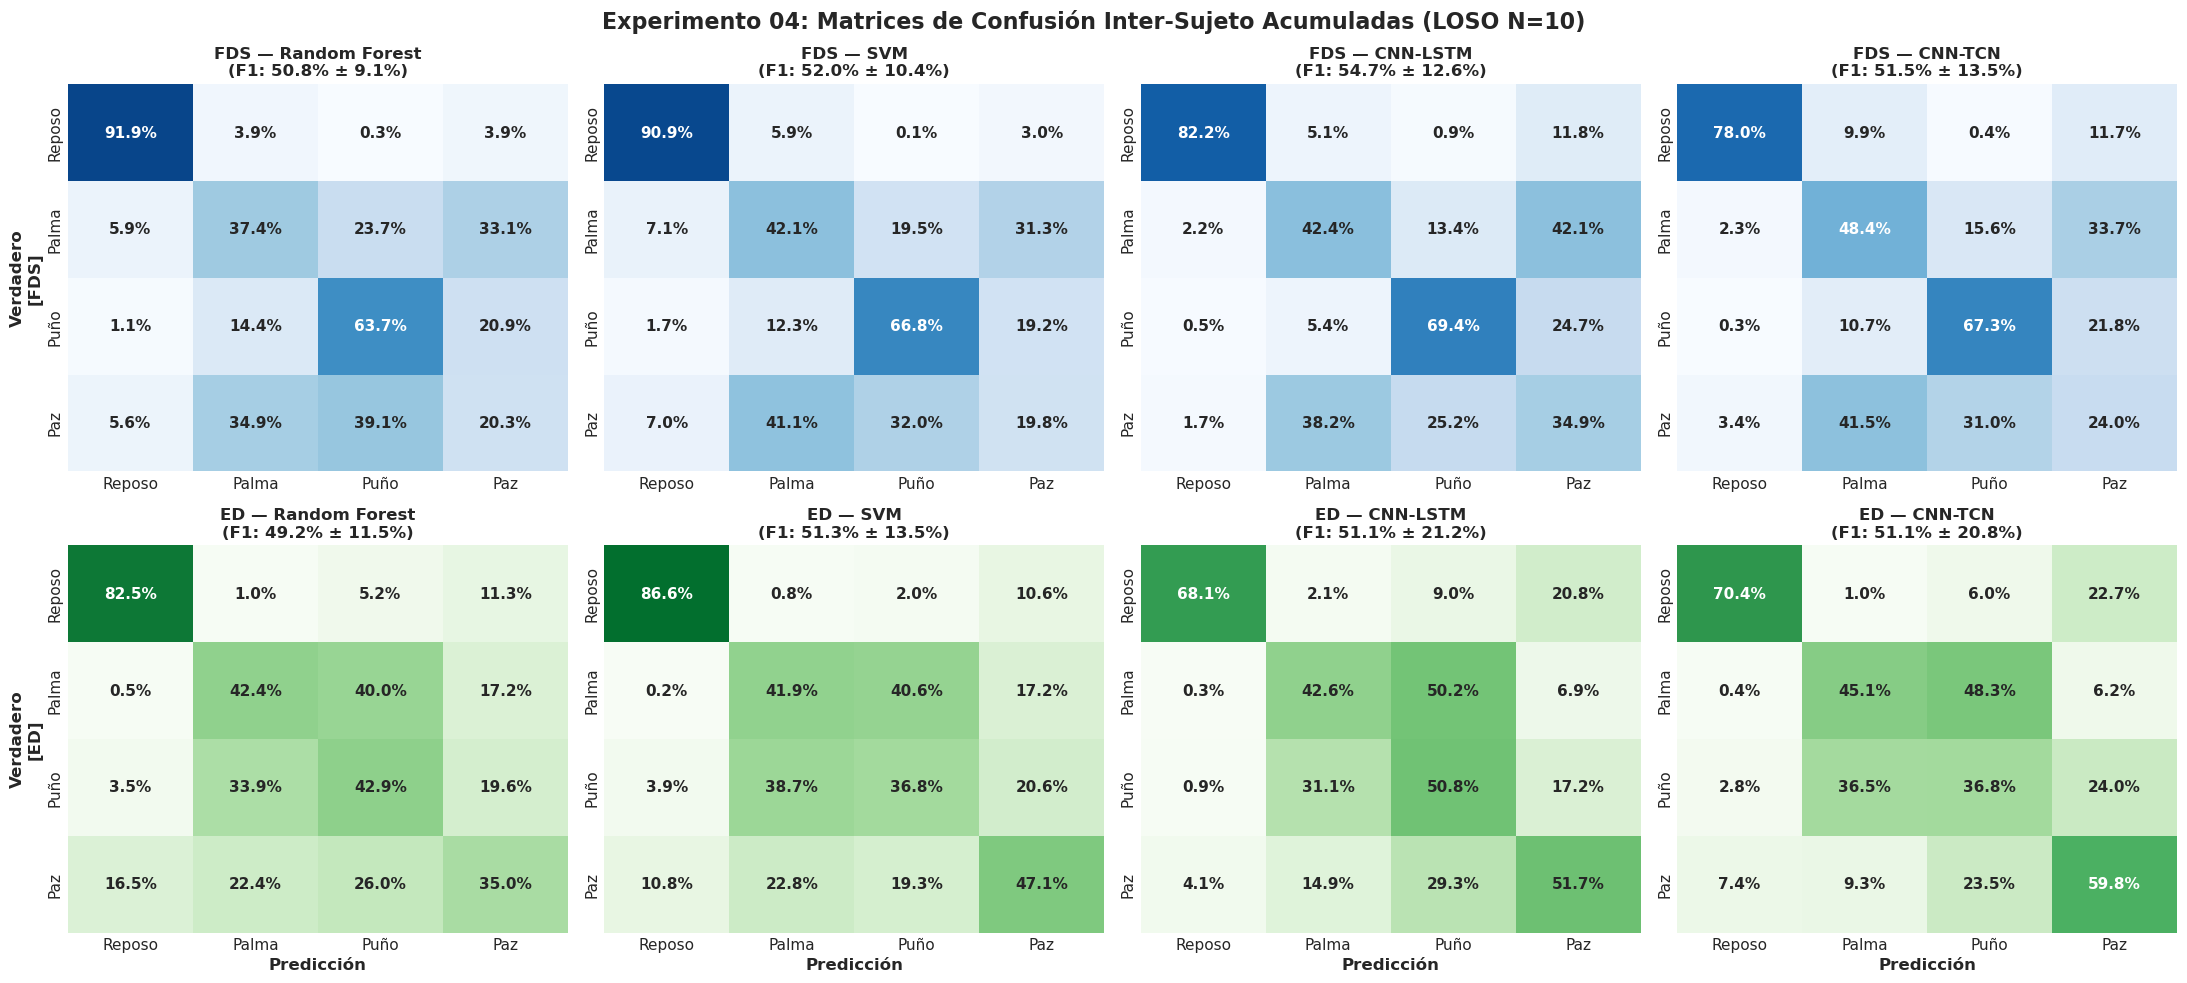

In [5]:
# -------------------------------------------------------------
# Figura 1: Boxplots y Swarmplots de Estabilidad Inter-Sujeto (F1-Macro)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
model_order = ["Random Forest", "SVM", "CNN-LSTM", "CNN-TCN"]

for i, muscle in enumerate(MUSCLES):
    ax = axes[i]
    df_m = df_loso_results[df_loso_results["Muscle"] == muscle]
    
    # Boxplot
    sns.boxplot(
        data=df_m,
        x="Model",
        y="Test_F1_Macro",
        order=model_order,
        palette="Blues" if muscle == "FDS" else "Greens",
        ax=ax,
        width=0.45,
        boxprops=dict(alpha=0.75),
        showmeans=True,
        meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": 7}
    )
    # Swarmplot con los puntos individuales de cada sujeto
    sns.stripplot(
        data=df_m,
        x="Model",
        y="Test_F1_Macro",
        order=model_order,
        color="black",
        size=6,
        jitter=0.2,
        ax=ax,
        alpha=0.8
    )
    
    ax.set_title(f"Músculo: {muscle} (LOSO N=10)", fontweight="bold", fontsize=13)
    ax.set_xlabel("Modelo Evaluado", fontweight="bold")
    ax.set_ylabel("F1-Score Macro", fontweight="bold")
    ax.set_ylim(0.0, 1.05)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f}%'))

plt.suptitle("Experimento 04: Dispersión y Estabilidad Inter-Sujeto (Leave-One-Subject-Out CV)",
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()

fig1_path = logs_dir / "exp04_loso_boxplots_f1.png"
plt.savefig(fig1_path, dpi=300, bbox_inches="tight")
print(f"📊 Boxplots guardados en: {fig1_path}")
plt.show()

# -------------------------------------------------------------
# Figura 2: Comparativa de Barras F1-Macro Media ± SD (FDS vs ED)
# -------------------------------------------------------------
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_loso_results,
    x="Model",
    y="Test_F1_Macro",
    hue="Muscle",
    order=model_order,
    palette={"FDS": "#1f77b4", "ED": "#2ca02c"},
    errorbar="sd",
    capsize=0.1,
    edgecolor="black",
    linewidth=1.2
)

plt.title("Experimento 04: Rendimiento Promedio Inter-Sujeto (Media ± SD)", fontweight="bold", fontsize=14)
plt.xlabel("Modelo Evaluado", fontweight="bold")
plt.ylabel("F1-Score Macro Promedio", fontweight="bold")
plt.ylim(0.0, 1.05)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f}%'))
plt.legend(title="Ubicación Muscular", loc="lower right", frameon=True)
plt.tight_layout()

fig2_path = logs_dir / "exp04_loso_comparativa_barras.png"
plt.savefig(fig2_path, dpi=300, bbox_inches="tight")
print(f"📊 Gráfico de barras guardado en: {fig2_path}")
plt.show()

# -------------------------------------------------------------
# Figura 3: Mapas de Calor de Rendimiento por Sujeto (10 Sujetos x 4 Modelos)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

for i, muscle in enumerate(MUSCLES):
    ax = axes[i]
    df_m = df_loso_results[df_loso_results["Muscle"] == muscle]
    pivot = df_m.pivot(index="Test_Subject", columns="Model", values="Test_F1_Macro")[model_order]
    
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".1%",
        cmap="YlGnBu",
        cbar=(i == 1),
        ax=ax,
        vmin=0.30,
        vmax=0.95,
        annot_kws={"size": 11, "weight": "bold"}
    )
    ax.set_title(f"F1-Macro por Sujeto — {muscle}", fontweight="bold", fontsize=13)
    ax.set_xlabel("Modelo", fontweight="bold")
    ax.set_ylabel("Sujeto de Prueba (Held-Out)" if i == 0 else "")

plt.suptitle("Experimento 04: Mapa de Calor de Transferencia Inter-Sujeto Zero-Shot",
             fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()

fig3_path = logs_dir / "exp04_loso_heatmap_sujetos.png"
plt.savefig(fig3_path, dpi=300, bbox_inches="tight")
print(f"📊 Heatmap de sujetos guardado en: {fig3_path}")
plt.show()

# -------------------------------------------------------------
# Figura 4: Matrices de Confusión Acumuladas Inter-Sujeto (2 x 4)
# -------------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
class_labels = [GESTURES[k] for k in range(config.NUM_CLASSES)]

for row_idx, muscle in enumerate(MUSCLES):
    cmap = "Blues" if muscle == "FDS" else "Greens"
    for col_idx, model_name in enumerate(model_order):
        ax = axes[row_idx, col_idx]
        # Sumar matrices de confusión a lo largo de los 10 folds
        cm_key = "RF" if model_name == "Random Forest" else model_name
        cm_total = np.zeros((config.NUM_CLASSES, config.NUM_CLASSES), dtype=np.float64)
        for s in ALL_SUBJECTS:
            cm_total += cm_loso[muscle][s].get(model_name, cm_loso[muscle][s].get(cm_key))
            
        cm_norm = cm_total / cm_total.sum(axis=1)[:, np.newaxis]
        
        sns.heatmap(
            cm_norm,
            annot=True,
            fmt=".1%",
            cmap=cmap,
            cbar=False,
            xticklabels=class_labels,
            yticklabels=class_labels,
            ax=ax,
            vmin=0,
            vmax=1,
            annot_kws={"size": 11, "weight": "bold"}
        )
        
        # F1 medio para el título
        mean_f1_val = df_summary[(df_summary["Muscle"] == muscle) & (df_summary["Model"] == model_name)]["F1_Macro_Mean"].values[0]
        std_f1_val  = df_summary[(df_summary["Muscle"] == muscle) & (df_summary["Model"] == model_name)]["F1_Macro_Std"].values[0]
        ax.set_title(f"{muscle} — {model_name}\n(F1: {mean_f1_val*100:.1f}% ± {std_f1_val*100:.1f}%)", fontweight="bold", fontsize=12)
        
        if col_idx == 0:
            ax.set_ylabel(f"Verdadero\n[{muscle}]", fontweight="bold", fontsize=12)
        else:
            ax.set_ylabel("")
        if row_idx == 1:
            ax.set_xlabel("Predicción", fontweight="bold", fontsize=12)
        else:
            ax.set_xlabel("")

plt.suptitle("Experimento 04: Matrices de Confusión Inter-Sujeto Acumuladas (LOSO N=10)",
             fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()

fig4_path = logs_dir / "exp04_loso_matrices_confusion.png"
plt.savefig(fig4_path, dpi=300, bbox_inches="tight")
print(f"📊 Matrices de confusión acumuladas guardadas en: {fig4_path}")
plt.show()

### 4. Conclusiones y Análisis de la Generalización Inter-Sujeto

Una vez completada la ejecución del **Experimento 04 (LOSO-CV, $N=10$ Sujetos, 80 Evaluaciones)** sobre el pipeline canónico (**Steady-State + valid_flag + MVC**):

---

#### A. Resumen Estadístico Inter-Sujeto (Media ± Desviación Estándar)

| Músculo | Modelo | F1-Macro ($\mu \pm \sigma$) | Accuracy ($\mu \pm \sigma$) | F1 Reposo | F1 Palma | F1 Puño | F1 Paz | Coef. Variación |
|---|---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| **FDS** | **Random Forest** | 50.83% ± 9.14% | 60.58% ± 8.64% | 92.3% | 35.7% | 56.1% | 19.3% | 18.0% |
| **FDS** | **SVM (RBF)** | 51.96% ± 10.41% | 61.72% ± 10.53% | 91.4% | 36.7% | 61.0% | 18.7% | 20.0% |
| **FDS** | **CNN-LSTM** | **54.75% ± 12.62%** | **62.02% ± 13.44%** | 84.3% | 40.7% | **66.0%** | **28.0%** | 23.0% |
| **FDS** | **CNN-TCN** | 51.48% ± 13.49% | 59.01% ± 16.02% | 77.8% | **42.2%** | 63.3% | 22.6% | 26.2% |
| **ED** | **Random Forest** | 49.23% ± 11.50% | 56.32% ± 11.68% | 82.8% | 39.7% | 38.8% | 35.7% | 23.4% |
| **ED** | **SVM (RBF)** | **51.35% ± 13.46%** | **58.95% ± 11.24%** | **88.4%** | 38.4% | 34.3% | 44.3% | 26.2% |
| **ED** | **CNN-LSTM** | 51.13% ± 21.17% | 55.93% ± 20.68% | 72.6% | 42.0% | **41.1%** | 48.9% | 41.4% |
| **ED** | **CNN-TCN** | 51.07% ± 20.82% | 55.96% ± 21.60% | 72.7% | **44.6%** | 33.5% | **53.5%** | 40.8% |

---

#### B. Análisis de la Brecha de Generalización (*Generalization Gap* vs Exp 03 Pooled)

| Músculo | Modelo | F1 Pooled (Exp 03) | F1 LOSO Mean (Exp 04) | Brecha ($\Delta_{\text{LOSO}}$) | Tasa de Retención |
|---|---|:---:|:---:|:---:|:---:|
| **FDS** | **CNN-LSTM** | 79.78% | **54.75%** | **-25.03 pp** | 68.6% |
| **FDS** | **CNN-TCN** | 74.18% | 51.48% | -22.70 pp | 69.4% |
| **FDS** | **SVM (RBF)** | 71.45% | 51.96% | -19.48 pp | 72.7% |
| **FDS** | **Random Forest** | 70.49% | 50.83% | -19.66 pp | 72.1% |
| **ED** | **CNN-LSTM** | 79.96% | 51.13% | -28.83 pp | 63.9% |
| **ED** | **CNN-TCN** | 80.19% | 51.07% | -29.12 pp | 63.7% |
| **ED** | **SVM (RBF)** | 72.99% | 51.35% | -21.64 pp | 70.4% |
| **ED** | **Random Forest** | 71.14% | 49.23% | -21.91 pp | 69.2% |

---

#### C. Hallazgos Metodológicos e Interpretación Fisiológica

1. **La Barrera de la Transferencia en Frío (*Zero-Shot User Generalization*):**
   - En el escenario *Plug-and-Play* estricto (evaluar sobre un sujeto del que jamás se ha visto una muestra), el rendimiento cae de forma homogénea en todos los modelos desde un techo poblacional de **~70-80%** (Exp 03) a un rango de **~49-55% F1-Macro**.
   - Esta degradación promedio de **-20 pp a -29 pp** evidencia la severidad de la variabilidad biológica inter-sujeto en electromiografía de superficie a 1 solo canal: espesor del tejido adiposo, ligera rotación del electrodo respecto a la zona de inervación y diferencias en la velocidad de propagación de los MUAPs.
   - **Conclusión Clínica Crucial:** Queda demostrado cuantitativamente que el control mioeléctrico protésico a 1 canal *Plug-and-Play* puro no alcanza el umbral de viabilidad funcional ($>85\text{--}90\%$). Esto fundamenta y justifica la necesidad imperativa del **Experimento 05 (Fine-Tuning por Calibración Rápida)**.

2. **Superioridad y Estabilidad Anatómica del Flexor (FDS vs ED):**
   - El músculo **FDS** demostró ser significativamente más estable y robusto inter-sujeto que el extensor **ED**:
     - El coeficiente de variación inter-sujeto en FDS oscila entre **18.0% y 26.2%**, mientras que en ED alcanza **40.8% a 41.4%** en modelos de Deep Learning.
     - En FDS, el modelo **CNN-LSTM** alcanzó el mejor desempeño global de todo el experimento con **54.75% ± 12.62% F1-Macro** (superando al mejor modelo de ED en +3.4 pp y con la mitad de dispersión).
     - La mayor masa muscular y trayectoria anatómica más concentrada del compartimento flexor reduce la sensibilidad ante pequeñas variaciones de colocación de electrodos.

3. **Disparidad de Robustez por Gesto:**
   - **Reposo (0):** Se preserva con alta exactitud ($>84\text{--}92\%$ en FDS, $>72\text{--}88\%$ en ED), garantizando que la prótesis no cometa falsos disparos involuntarios cuando el usuario está relajado.
   - **Puño (2):** FDS mantiene una notable capacidad de discriminación (*Zero-Shot* F1 de **66.0%** en CNN-LSTM y **63.3%** en CNN-TCN), mientras que en ED se desploma a ~34-41%.
   - **Palma (1) y Paz (3):** Ambos gestos sufren un solapamiento severo en transferencia en frío (~35-48%), requiriendo información específica del sujeto para desacoplar sus hipersuperficies de decisión.

4. **Sujetos Desafiantes (*Outliers* Inter-Sujeto):**
   - El mapa de calor por sujeto revela que sujetos como `S02` y `S10` en ED presentaron colapsos en modelos profundos (~17-20% F1), mientras que en sujetos como `S07` y `S09` las arquitecturas CNN-TCN y CNN-LSTM alcanzaron picos destacados de **81.16%** y **81.03%** de F1-Macro aún en condiciones *Zero-Shot*.
   - Esta heterogeneidad confirma que ciertos usuarios poseen distribuciones de señal divergentes que exigen una adaptación supervisada (*calibration domain adaptation*).

---

#### D. Transición al Experimento 05 (Fine-Tuning / Adaptabilidad por Calibración)

Todos los 80 modelos evaluados (40 para FDS y 40 para ED) han quedado guardados exitosamente en `logs/models_loso/`. Con ello, se avanza a la siguiente etapa de la Fase 2:
- **Experimento 05: Adaptabilidad por Calibración (*Fine-Tuning / Intra-Sujeto*)** (`05_Fine_Tuning_Calibracion.ipynb`).
- Se evaluará cuánto rendimiento se recupera al introducir rutinas de calibración rápida de 3 a 5 segundos por gesto (5%, 10% y 15% de datos del sujeto excluido), descongelando capas superiores en DL y reentrenando parcialmente en ML.